In [ ]:
pip install pandas numpy matplotlib mplfinance seaborn

In [ ]:
#importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf


In [ ]:
# Step 2: Load the stock market dataset

df = pd.read_csv("/content/AAPL_stock_data.csv")



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10971 entries, 0 to 10970
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10971 non-null  object 
 1   open        10971 non-null  float64
 2   high        10971 non-null  float64
 3   low         10971 non-null  float64
 4   close       10971 non-null  float64
 5   adjclose    10971 non-null  float64
 6   volume      10971 non-null  int64  
 7   ticker      10971 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 685.8+ KB


In [ ]:
# Display first 5 rows

print(df.head())

   Unnamed: 0      open      high       low     close  adjclose     volume  \
0  1980-12-12  0.128348  0.128906  0.128348  0.128348  0.099192  469033600   
1  1980-12-15  0.122210  0.122210  0.121652  0.121652  0.094017  175884800   
2  1980-12-16  0.113281  0.113281  0.112723  0.112723  0.087117  105728000   
3  1980-12-17  0.115513  0.116071  0.115513  0.115513  0.089273   86441600   
4  1980-12-18  0.118862  0.119420  0.118862  0.118862  0.091861   73449600   

  ticker  
0   AAPL  
1   AAPL  
2   AAPL  
3   AAPL  
4   AAPL  


In [ ]:
# Dataset dimensions

print("Dataset shape:", df.shape)

Dataset shape: (10971, 8)


In [ ]:
# Display column names

print("Column names:")
print(df.columns)

Column names:
Index(['Unnamed: 0', 'open', 'high', 'low', 'close', 'adjclose', 'volume',
       'ticker'],
      dtype='object')


In [ ]:
# Statistical summary of numerical columns

print(df.describe())

               open          high           low         close      adjclose  \
count  10971.000000  10971.000000  10971.000000  10971.000000  10971.000000   
mean      21.808152     22.043474     21.583133     21.822430     21.054940   
std       44.979785     45.464424     44.531168     45.017703     44.632965   
min        0.049665      0.049665      0.049107      0.049107      0.037952   
25%        0.297991      0.303571      0.290179      0.297991      0.242262   
50%        0.526786      0.535357      0.515625      0.526786      0.429012   
75%       19.920358     20.134821     19.730357     19.908214     17.172640   
max      217.589996    220.199997    213.000000    216.669998    216.669998   

             volume  
count  1.097100e+04  
mean   3.187071e+08  
std    3.356215e+08  
min    0.000000e+00  
25%    1.136572e+08  
50%    2.061696e+08  
75%    3.990980e+08  
max    7.421641e+09  


In [ ]:
# Check missing values in each column

print("Missing values:")
print(df.isnull().sum())

Missing values:
Unnamed: 0    0
open          0
high          0
low           0
close         0
adjclose      0
volume        0
ticker        0
dtype: int64


In [ ]:
# Step 3: Data preprocessing

# Reload original dataset
df = pd.read_csv("/content/AAPL_stock_data.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Rename Unnamed: 0 to Date
df.rename(columns={'Unnamed: 0': 'Date'}, inplace=True)

# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Sort records chronologically
df = df.sort_values(by='Date')

# Remove duplicate records
df = df.drop_duplicates(subset='Date')

# Handle missing values
df = df.dropna()

# Set Date as index
df = df.set_index('Date')

print("Preprocessing completed successfully!")

# Display cleaned data
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Preprocessing completed successfully!

First 5 rows:
                open      high       low     close  adjclose     volume ticker
Date                                                                          
1980-12-12  0.128348  0.128906  0.128348  0.128348  0.099192  469033600   AAPL
1980-12-15  0.122210  0.122210  0.121652  0.121652  0.094017  175884800   AAPL
1980-12-16  0.113281  0.113281  0.112723  0.112723  0.087117  105728000   AAPL
1980-12-17  0.115513  0.116071  0.115513  0.115513  0.089273   86441600   AAPL
1980-12-18  0.118862  0.119420  0.118862  0.118862  0.091861   73449600   AAPL

Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10971 entries, 1980-12-12 to 2024-06-20
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   open      10971 non-null  float64
 1   high      10971 non-null  float64
 2   low       10971 non-null  float64
 3   close     10971 non-null  float64
 4   adjclose

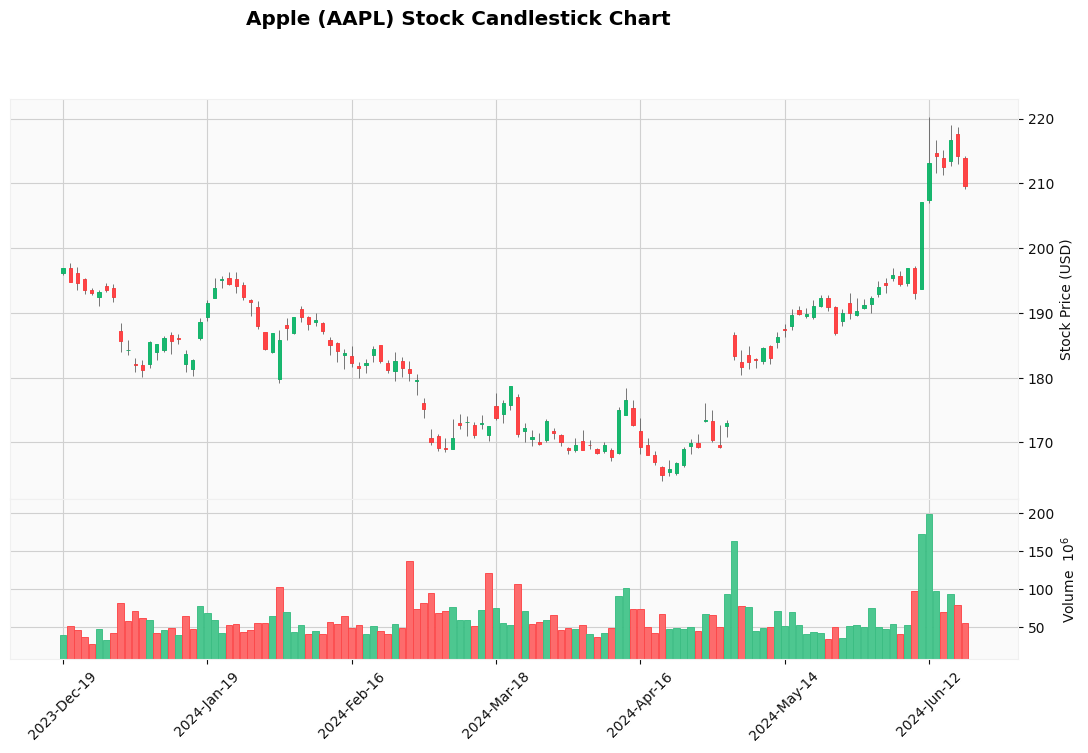

In [ ]:
# Step 4: Candlestick chart

# Rename columns to the format required by mplfinance
ohlc = df.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close',
    'volume': 'Volume'
})

# Select recent 6 months of data for better visualization
recent_data = ohlc.tail(126)

# Plot candlestick chart
mpf.plot(
    recent_data,
    type='candle',
    style='yahoo',
    title='Apple (AAPL) Stock Candlestick Chart',
    ylabel='Stock Price (USD)',
    volume=True,
    figsize=(14, 8)
)

plt.show()

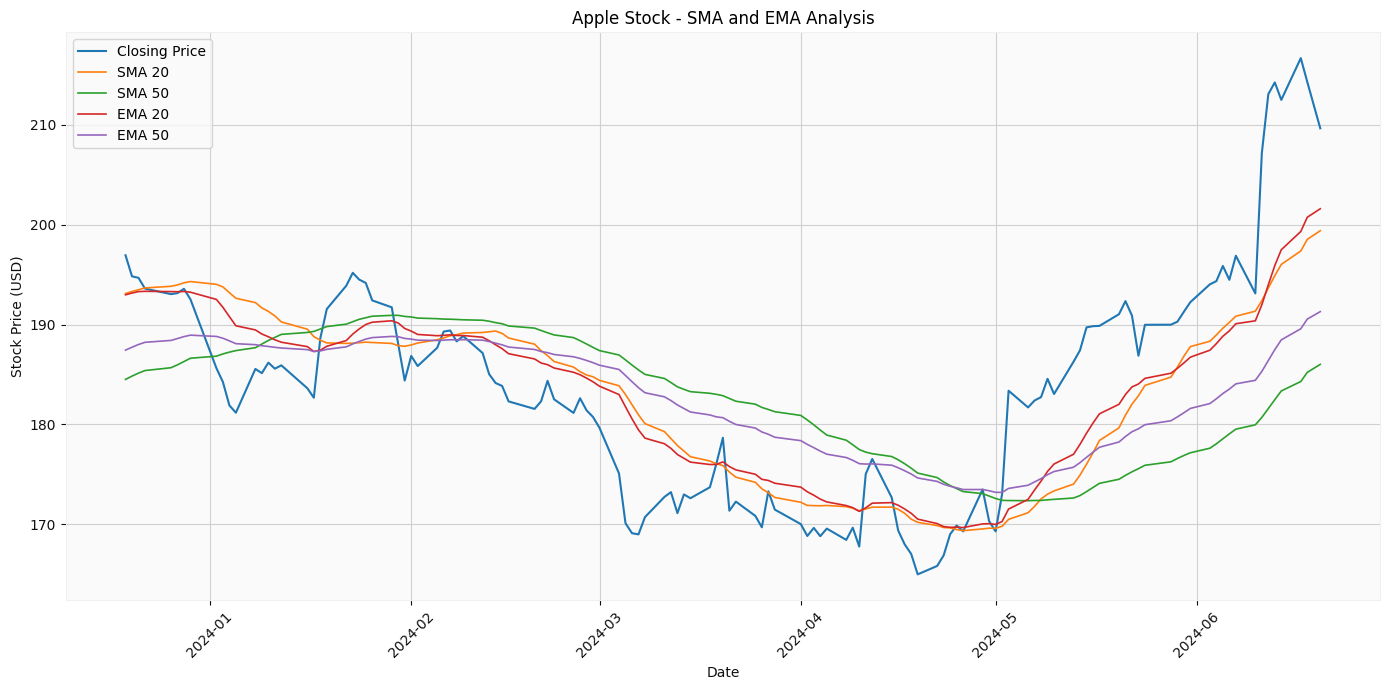

In [ ]:
# Step 5: SMA and EMA analysis

# Calculate Simple Moving Averages
df['SMA_20'] = df['close'].rolling(window=20).mean()
df['SMA_50'] = df['close'].rolling(window=50).mean()

# Calculate Exponential Moving Averages
df['EMA_20'] = df['close'].ewm(span=20, adjust=False).mean()
df['EMA_50'] = df['close'].ewm(span=50, adjust=False).mean()

# Select recent 6 months of data
plot_data = df.tail(126)

# Plot the chart
plt.figure(figsize=(14, 7))

plt.plot(plot_data.index, plot_data['close'],
         label='Closing Price', linewidth=1.5)

plt.plot(plot_data.index, plot_data['SMA_20'],
         label='SMA 20', linewidth=1.2)

plt.plot(plot_data.index, plot_data['SMA_50'],
         label='SMA 50', linewidth=1.2)

plt.plot(plot_data.index, plot_data['EMA_20'],
         label='EMA 20', linewidth=1.2)

plt.plot(plot_data.index, plot_data['EMA_50'],
         label='EMA 50', linewidth=1.2)

plt.title('Apple Stock - SMA and EMA Analysis')
plt.xlabel('Date')
plt.ylabel('Stock Price (USD)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

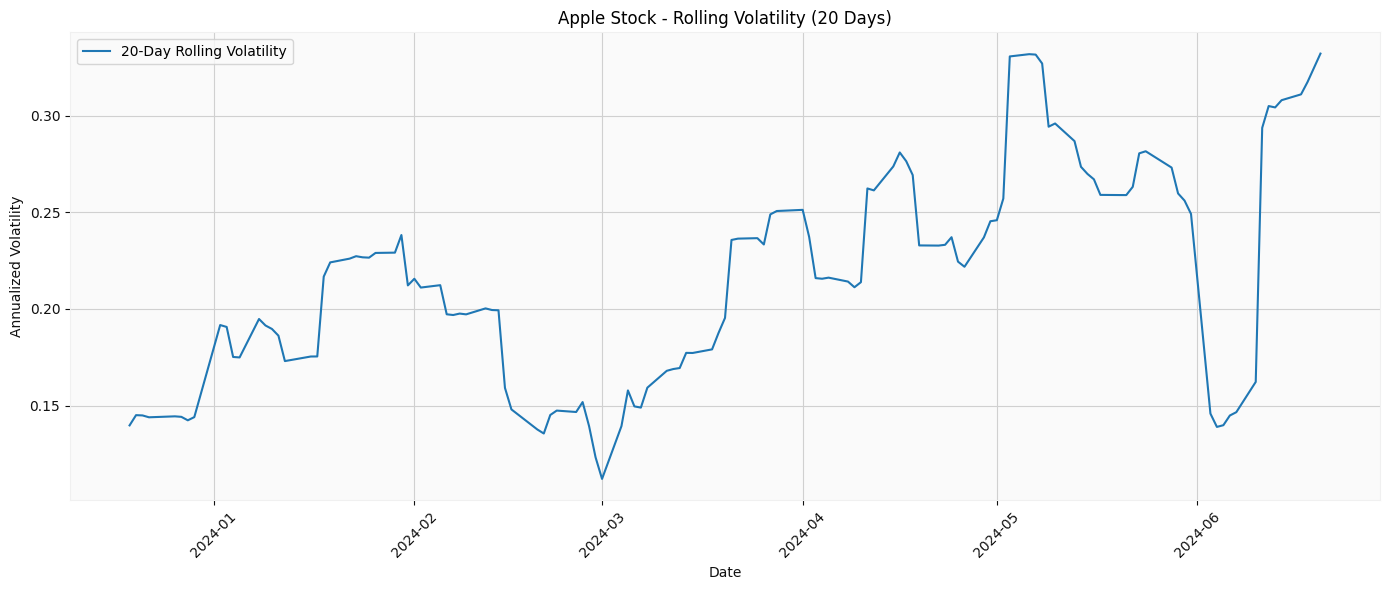

In [ ]:
# Step 6A: Rolling Volatility Analysis

# Calculate daily returns
df['Daily_Return'] = df['close'].pct_change()

# Calculate 20-day rolling volatility
df['Rolling_Volatility'] = (
    df['Daily_Return'].rolling(window=20).std() * np.sqrt(252)
)

# Select recent 6 months
plot_data = df.tail(126)

# Plot rolling volatility
plt.figure(figsize=(14, 6))

plt.plot(
    plot_data.index,
    plot_data['Rolling_Volatility'],
    label='20-Day Rolling Volatility',
    linewidth=1.5
)

plt.title('Apple Stock - Rolling Volatility (20 Days)')
plt.xlabel('Date')
plt.ylabel('Annualized Volatility')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

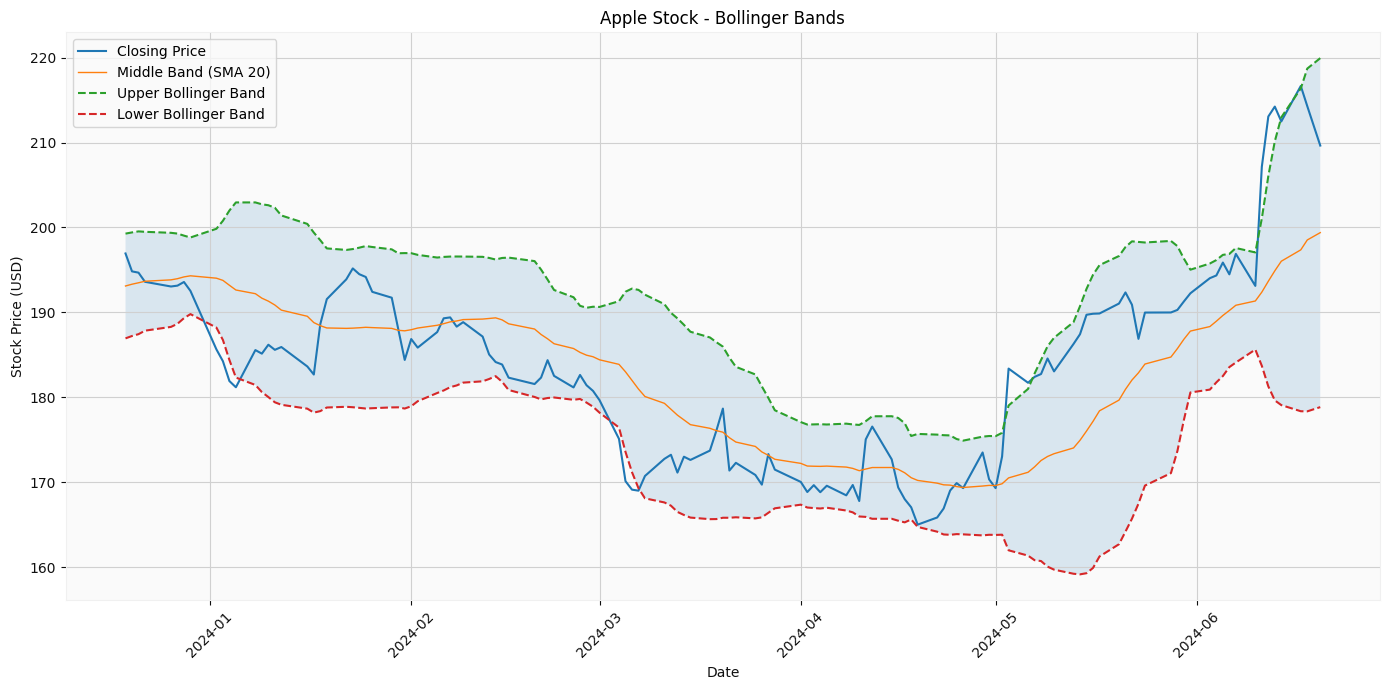

In [ ]:
# Step 6B: Bollinger Bands Analysis

# Calculate 20-day moving average
df['BB_Middle'] = df['close'].rolling(window=20).mean()

# Calculate 20-day standard deviation
df['BB_Std'] = df['close'].rolling(window=20).std()

# Calculate upper and lower bands
df['BB_Upper'] = df['BB_Middle'] + (2 * df['BB_Std'])
df['BB_Lower'] = df['BB_Middle'] - (2 * df['BB_Std'])

# Select recent 6 months
plot_data = df.tail(126)

# Plot Bollinger Bands
plt.figure(figsize=(14, 7))

plt.plot(plot_data.index, plot_data['close'],
         label='Closing Price', linewidth=1.5)

plt.plot(plot_data.index, plot_data['BB_Middle'],
         label='Middle Band (SMA 20)', linewidth=1)

plt.plot(plot_data.index, plot_data['BB_Upper'],
         label='Upper Bollinger Band', linestyle='--')

plt.plot(plot_data.index, plot_data['BB_Lower'],
         label='Lower Bollinger Band', linestyle='--')

plt.fill_between(
    plot_data.index,
    plot_data['BB_Lower'],
    plot_data['BB_Upper'],
    alpha=0.15
)

plt.title('Apple Stock - Bollinger Bands')
plt.xlabel('Date')
plt.ylabel('Stock Price (USD)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

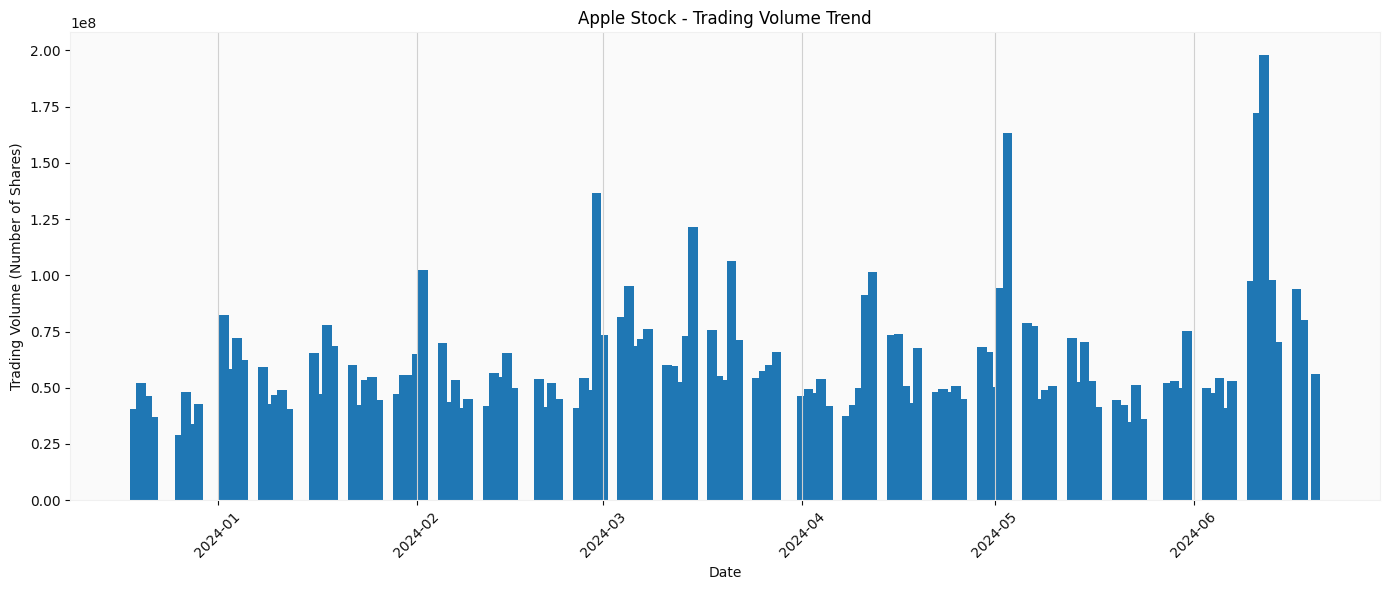

In [ ]:
# Step 7A: Trading Volume Trend Analysis

# Select recent 6 months of data
plot_data = df.tail(126)

# Plot trading volume
plt.figure(figsize=(14, 6))

plt.bar(
    plot_data.index,
    plot_data['volume'],
    width=1.5
)

plt.title('Apple Stock - Trading Volume Trend')
plt.xlabel('Date')
plt.ylabel('Trading Volume (Number of Shares)')
plt.grid(axis='y')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

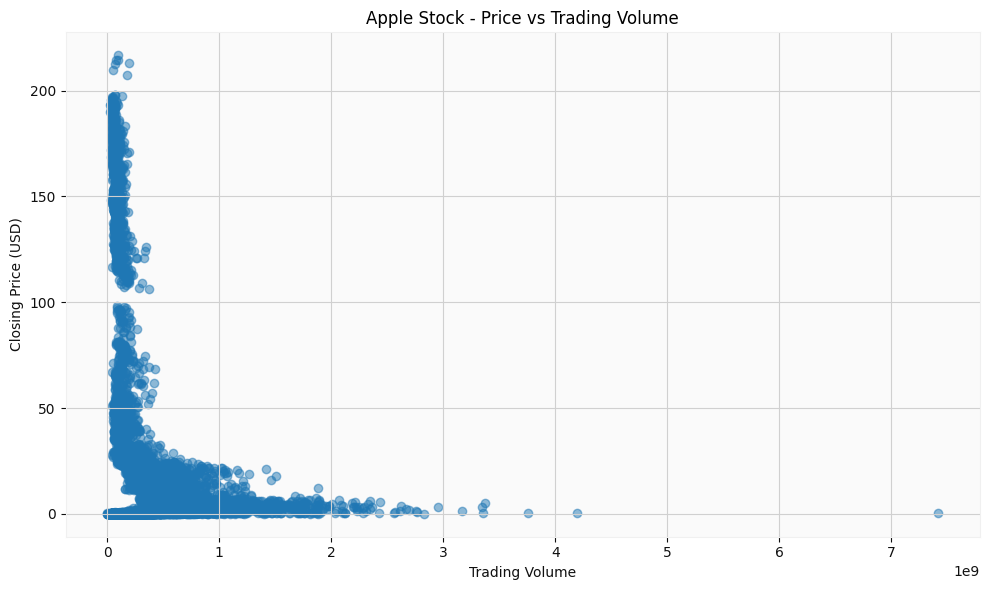

In [ ]:
# Step 7B: Stock Price vs Trading Volume

plt.figure(figsize=(10, 6))

plt.scatter(
    df['volume'],
    df['close'],
    alpha=0.5
)

plt.title('Apple Stock - Price vs Trading Volume')
plt.xlabel('Trading Volume')
plt.ylabel('Closing Price (USD)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Step 8A: Monthly Returns Analysis

# Calculate monthly closing prices
monthly_close = df['close'].resample('ME').last()

# Calculate monthly percentage returns
monthly_returns = monthly_close.pct_change() * 100

print("Monthly Returns:")
print(monthly_returns.tail(12))

Monthly Returns:
Date
2023-07-31     1.278546
2023-08-31    -4.367525
2023-09-30    -8.867828
2023-10-31    -0.256996
2023-11-30    11.231476
2023-12-31     1.358253
2024-01-31    -4.222721
2024-02-29    -1.979389
2024-03-31    -5.128633
2024-04-30    -0.670629
2024-05-31    12.869135
2024-06-30     9.050609
Freq: ME, Name: close, dtype: float64


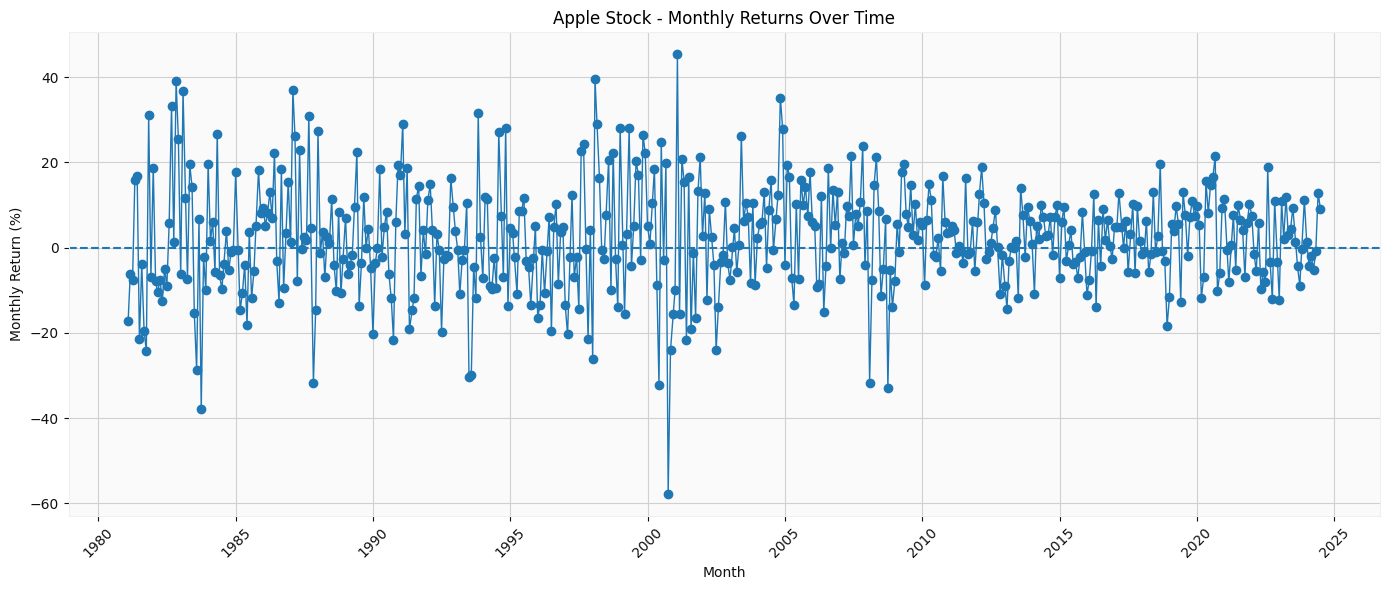

In [ ]:
# Plot monthly returns over time

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_returns.index,
    monthly_returns,
    marker='o',
    linewidth=1
)

plt.axhline(0, linestyle='--')

plt.title('Apple Stock - Monthly Returns Over Time')
plt.xlabel('Month')
plt.ylabel('Monthly Return (%)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

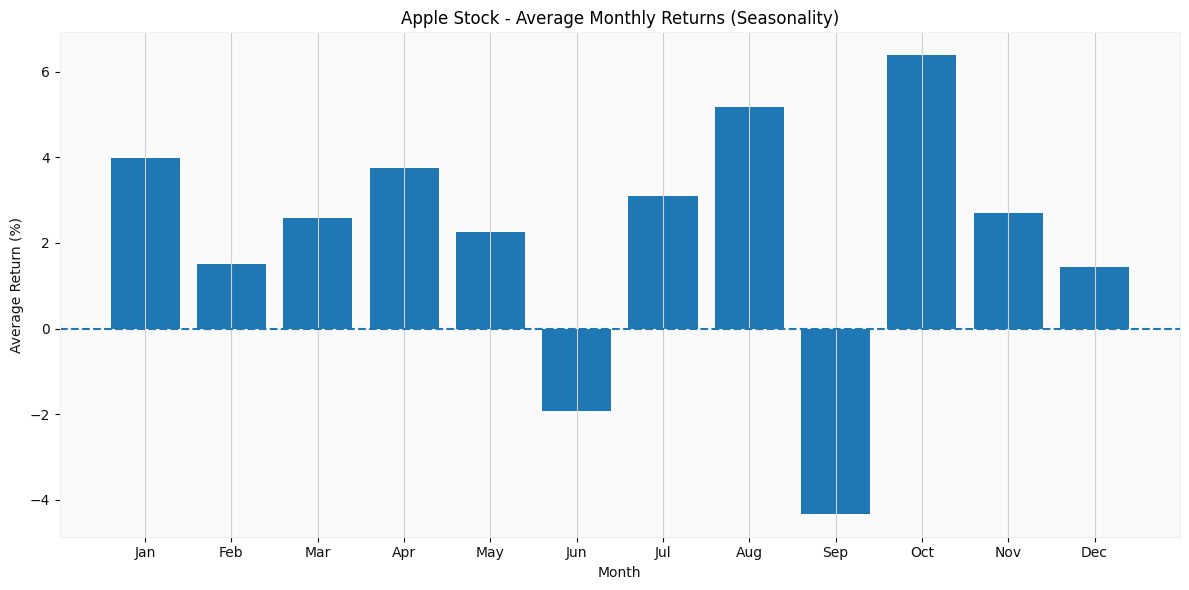

In [ ]:
# Step 8B: Monthly Seasonality Analysis

# Group returns by calendar month
monthly_seasonality = monthly_returns.groupby(
    monthly_returns.index.month
).mean()

# Month names
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

# Plot average monthly returns
plt.figure(figsize=(12, 6))

plt.bar(month_names, monthly_seasonality.values)

plt.axhline(0, linestyle='--')

plt.title('Apple Stock - Average Monthly Returns (Seasonality)')
plt.xlabel('Month')
plt.ylabel('Average Return (%)')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

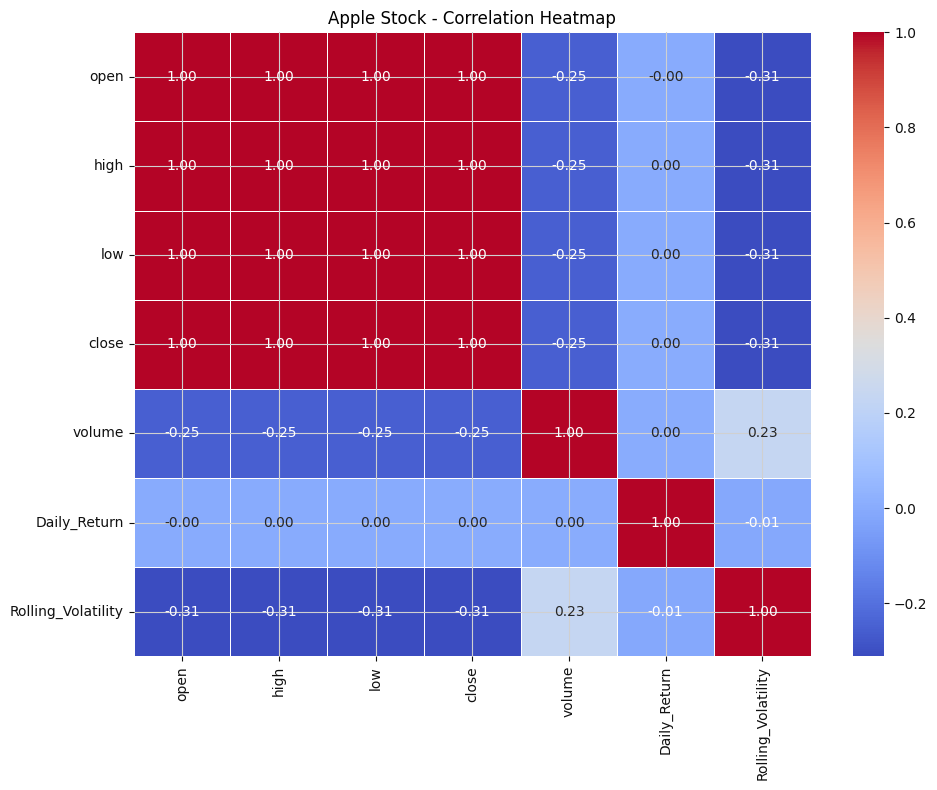

In [ ]:
# Step 9A: Correlation Analysis

# Select variables for correlation
correlation_data = df[
    ['open', 'high', 'low', 'close', 'volume',
     'Daily_Return', 'Rolling_Volatility']
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Apple Stock - Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
# Step 9B: Detect Significant Price Changes

# Calculate the threshold
mean_return = df['Daily_Return'].mean()
std_return = df['Daily_Return'].std()

upper_threshold = mean_return + (2 * std_return)
lower_threshold = mean_return - (2 * std_return)

# Identify unusually large positive and negative returns
significant_changes = df[
    (df['Daily_Return'] > upper_threshold) |
    (df['Daily_Return'] < lower_threshold)
].copy()

# Convert returns to percentage
significant_changes['Return_Percentage'] = (
    significant_changes['Daily_Return'] * 100
)

# Display important columns
print("Significant Stock Price Changes:")

print(
    significant_changes[
        ['close', 'volume', 'Return_Percentage']
    ].sort_values(
        by='Return_Percentage',
        key=lambda x: x.abs(),
        ascending=False
    ).head(15)
)

Significant Stock Price Changes:
               close      volume  Return_Percentage
Date                                               
2000-09-29  0.459821  7421640800         -51.869199
1997-08-06  0.234933  4190480000          33.228046
1983-09-23  0.108259  2832345600         -25.384420
1987-10-19  0.325893   476000000         -24.352373
1998-01-02  0.145089   718110400          23.808753
1996-07-18  0.186384   897052800          23.703457
1993-07-16  0.245536  2120596800         -23.076727
1987-10-26  0.250000   313600000         -21.126690
1998-01-06  0.169085  1812473600          19.291528
1993-10-15  0.252232   955248000          18.947054
2008-09-29  3.759286  2622057200         -17.919520
1987-10-29  0.352679   331520000          17.910658
1997-01-06  0.159598  1882832000         -17.816025
1987-10-21  0.361607   534240000          17.391145
2001-07-18  0.371250  1137012800         -17.171260


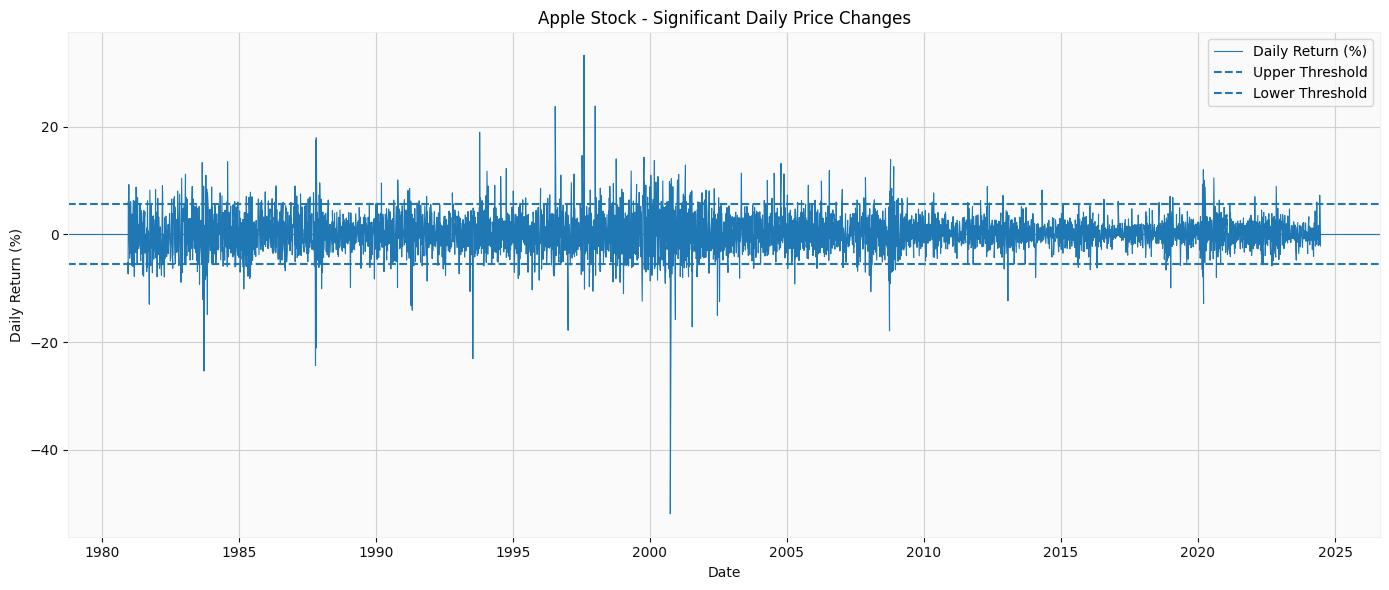

In [ ]:
# Plot daily returns and significant changes

plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df['Daily_Return'] * 100,
    label='Daily Return (%)',
    linewidth=0.8
)

plt.axhline(
    upper_threshold * 100,
    linestyle='--',
    label='Upper Threshold'
)

plt.axhline(
    lower_threshold * 100,
    linestyle='--',
    label='Lower Threshold'
)

plt.axhline(0, linewidth=0.8)

plt.title('Apple Stock - Significant Daily Price Changes')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Final Inference

print("\n========== INFERENCE ==========")

print("""
The time-series analysis of Apple stock data revealed variations in stock prices,
trading volume, and market volatility over time.

Candlestick charts helped identify bullish and bearish movements, while SMA and
EMA indicators highlighted short-term and long-term trends.

Rolling volatility and Bollinger Bands showed periods of high and low price
fluctuations. Volume analysis revealed changes in trading activity, and monthly
return analysis helped identify positive and negative performance patterns.

Correlation analysis provided insights into relationships among stock variables,
while significant-change detection highlighted unusual price movements.

Thus, Python visualizations effectively helped analyze historical stock trends,
variability, seasonal patterns, and market behavior.
""")

print("============================")


========== INFERENCE ==========

The time-series analysis of Apple stock data revealed variations in stock prices,
trading volume, and market volatility over time.

Candlestick charts helped identify bullish and bearish movements, while SMA and
EMA indicators highlighted short-term and long-term trends.

Rolling volatility and Bollinger Bands showed periods of high and low price
fluctuations. Volume analysis revealed changes in trading activity, and monthly
return analysis helped identify positive and negative performance patterns.

Correlation analysis provided insights into relationships among stock variables,
while significant-change detection highlighted unusual price movements.

Thus, Python visualizations effectively helped analyze historical stock trends,
variability, seasonal patterns, and market behavior.

